# Figures for the report

**Figure 1 (artificial data section).** The artificial data curve from Section 4.2:

$$s(\lambda) = 1 + (B - 1)\,\Phi\!\left(\frac{\lambda - \lambda_0}{w}\right), \qquad \lambda_0 = 4000\,\text{Å}$$

where $s$ is the rest-frame spectrum (flux per unit frequency), $B$ the break strength ($\approx D_n(4000)$) and $w$ the break width.
The observed spectrum at redshift $z$ is proportional to $s(\lambda / (1+z))$. Both panels are drawn over the SDSS $ugriz$ response curves (grey, each scaled to a peak of 1):

- **(a) Redshift.** The spectrum at the redshifts in `Z_VALUES`, offset vertically for clarity. As $z$ grows the break moves to the right, passing $u \to g$ at $z \approx 0.1$, $g \to r$ at $z \approx 0.36$ and $r \to i$ at $z \approx 0.71$.
- **(b) Break width.** A zoom on the $g/r$ boundary at $z = 0.36$, for each width in the A1 sweep. The spectrum is divided by $B$ so it shares an axis with the filter curves. Note that the observed width is $w(1+z)$.

**Figure 2 (a real spectrum, for reference).**

- **(a) A real galaxy.** The SDSS spectrum of a strong-break galaxy from our photometric sample, with its five catalogue magnitudes (converted to flux) at the filters' effective wavelengths. The spectrum is measured through a 3″ fibre, so it is scaled to match the catalogue $r$ magnitude, which measures the whole galaxy. The dotted line marks the observed position of the break, $4000(1+z)$ Å.
- **(b) Its break.** A zoom on the break, with the $D_n(4000)$ windows (3850–3950 and 4000–4100 Å in the rest frame) shaded and the mean flux in each drawn as a bar. Their ratio is $D_n(4000)$.

Change the parameters in the next cell and re-run. The figures are saved to `figures/artificial_spectrum.pdf` and `figures/real_spectrum.pdf`.

In [1]:
# Parameters
B = 1.6                              # break strength, roughly D_n(4000)
LAMBDA_0 = 4000.0                    # break wavelength in Angstrom
Z_VALUES = [0.10, 0.36, 0.71]        # redshifts in panel (a): near the u/g, g/r and r/i boundaries
W_SHOWN = 25                         # break width used in panel (a), in Angstrom
Z_ZOOM = 0.36                        # redshift used in panel (b)

# The real galaxy in Figure 2: a bright, high-S/N, strong-break galaxy (D_n(4000) = 2.04) from our sample
REAL_OBJ_ID = 1237667734518366228
REAL_SPECTRUM = "spec-2770-54510-0314.fits"   # SDSS plate-MJD-fibre of its spectrum

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from astropy.io import fits

from experiments.run_simulated_experiment import W_VALUES   # break widths in panel (b): the A1 sweep
from models.simulated_data import GenerateSpectrum, Redshift, LoadFilterCurves
from util.evaluation import BANDS

FILTER_URL = "https://www.sdss4.org/wp-content/uploads/2017/04/filter_curves.fits"
FILTER_PATH = Path("data/sdss_filter_curves.fits")
SPECTRUM_URL = "https://data.sdss.org/sas/dr18/spectro/sdss/redux/26/spectra/lite/{plate}/{name}"
SPECTRUM_PATH = Path("data") / REAL_SPECTRUM.replace("spec-", "sdss_spectrum_")
DATA_PATH = Path("data/sdss_galaxies_d4000.csv")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

GRID = np.arange(2900.0, 11500.0, 2.0)  # observed wavelength grid in Angstrom (2 A spacing)
SPEED_OF_LIGHT = 2.998e18               # in Angstrom per second
AB_ZERO_POINT_MJY = 3631e3              # flux of an AB magnitude of 0, in mJy

# Colours: an ordinal blue ramp for w (ordered values); ink for spectra; orange for the photometry
W_COLOURS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
PHOTOMETRY_COLOUR = "#eb6834"
SURFACE = "#ffffff"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
CONTEXT_FILL = "#e4e3df"   # filter curves: context, not data

plt.rcParams.update({
    "font.size": 8,
    "axes.edgecolor": INK_SECONDARY,
    "axes.labelcolor": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
    "savefig.bbox": "tight",
})

In [3]:
def download_once(url, path):
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)


def load_filter_curves():
    # Download the SDSS response curves once, then interpolate them onto GRID
    download_once(FILTER_URL, FILTER_PATH)
    return {band: np.interp(GRID, wavelength, response, left=0, right=0)
            for band, (wavelength, response) in LoadFilterCurves(FILTER_PATH).items()}


def band_average(f_nu, curve):
    # Mean of f_nu over a band, weighted by T_b(lambda) dlambda / lambda (the magnitude integral)
    return np.trapezoid(f_nu * curve / GRID, GRID) / np.trapezoid(curve / GRID, GRID)


def effective_wavelength(curve):
    # Mean wavelength of a band, with the same T_b(lambda) dlambda / lambda weighting
    return band_average(GRID, curve)


def load_real_spectrum():
    # Returns the observed wavelength (A), f_nu (mJy, fibre aperture) and redshift of the real galaxy
    download_once(SPECTRUM_URL.format(plate=REAL_SPECTRUM.split("-")[1], name=REAL_SPECTRUM), SPECTRUM_PATH)
    with fits.open(SPECTRUM_PATH) as hdul:
        spectrum = hdul[1].data
        info = hdul[2].data
        assert int(info["BESTOBJID"][0]) == REAL_OBJ_ID
        redshift = float(info["Z"][0])

    good = spectrum["ivar"] > 0                 # drop pixels the pipeline marks as unusable
    wavelength = 10 ** spectrum["loglam"][good]
    f_lambda = spectrum["flux"][good] * 1e-17   # erg / s / cm^2 / A
    f_nu = f_lambda * wavelength**2 / SPEED_OF_LIGHT / 1e-26   # 1 mJy = 1e-26 erg / s / cm^2 / Hz
    return wavelength, f_nu, redshift


def shade_filters(ax, bands, bottom, height):
    # Draw each filter curve, scaled to a peak of `height`, as a grey fill with its name above the peak
    for band in bands:
        curve = FILTERS[band] / FILTERS[band].max()
        ax.fill_between(GRID, bottom, bottom + height * curve, color=CONTEXT_FILL, lw=0, zorder=0)
        peak = GRID[np.argmax(curve)]
        ax.text(peak, bottom + 1.02 * height, band, ha="center", va="bottom",
                color=INK_SECONDARY, fontsize=8, style="italic")


FILTERS = load_filter_curves()

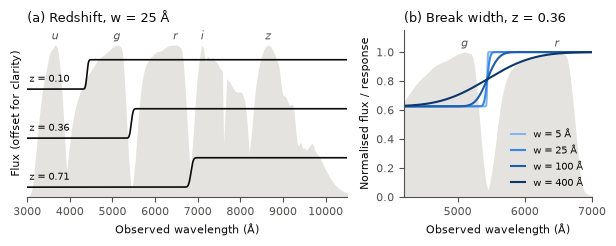

In [4]:
fig, (ax_z, ax_w) = plt.subplots(1, 2, figsize=(6.2, 2.5), gridspec_kw={"width_ratios": [1.7, 1]})

# (a) Redshift moves the break through the filters. Each spectrum gets its own lane.
lane_height = 1.0
shade_filters(ax_z, BANDS, bottom=0.8, height=len(Z_VALUES) * lane_height + 0.1)
for k, z in enumerate(Z_VALUES):
    offset = (len(Z_VALUES) - 1 - k) * lane_height   # lowest redshift in the top lane
    observed = Redshift(GenerateSpectrum(LAMBDA_0, B, W_SHOWN), z)(GRID)
    ax_z.plot(GRID, observed + offset, color=INK, lw=1.2)
    ax_z.text(3050, 1 + offset + 0.1, f"z = {z:.2f}", color=INK, fontsize=7.5, va="bottom")

ax_z.set_xlim(3000, 10500)
ax_z.set_ylim(0.8, 4.2)
ax_z.set_yticks([])
ax_z.spines["left"].set_visible(False)
ax_z.set_xlabel("Observed wavelength (Å)")
ax_z.set_ylabel("Flux (offset for clarity)")
ax_z.set_title(f"(a) Redshift, w = {W_SHOWN} Å", color=INK, fontsize=9, loc="left")

# (b) The break width, zoomed in on the g/r boundary
shade_filters(ax_w, ["g", "r"], bottom=0.0, height=1.0)
for w, colour in zip(W_VALUES, W_COLOURS):
    observed = Redshift(GenerateSpectrum(LAMBDA_0, B, w), Z_ZOOM)(GRID) / B
    ax_w.plot(GRID, observed, color=colour, label=f"w = {w} Å")

ax_w.set_xlim(4200, 7000)
ax_w.set_ylim(0, 1.15)
ax_w.set_xlabel("Observed wavelength (Å)")
ax_w.set_ylabel("Normalised flux / response")
ax_w.set_title(f"(b) Break width, z = {Z_ZOOM}", color=INK, fontsize=9, loc="left")
ax_w.legend(loc="lower right", labelcolor=INK, fontsize=7, handlelength=1.5)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "artificial_spectrum.pdf")
plt.show()

In [5]:
catalogue = pd.read_csv(DATA_PATH)
galaxy = catalogue[catalogue["objID"] == REAL_OBJ_ID].iloc[0]
spectrum_wavelength, spectrum_f_nu, spectrum_z = load_real_spectrum()

# Photometry: catalogue magnitudes as f_nu at each band's effective wavelength
band_wavelength = []
band_f_nu = []
for band in BANDS:
    band_wavelength.append(effective_wavelength(FILTERS[band]))
    band_f_nu.append(AB_ZERO_POINT_MJY * 10 ** (-0.4 * galaxy[band]))

# Scale the fibre spectrum so that its synthetic r-band flux matches the catalogue r magnitude
spectrum_on_grid = np.interp(GRID, spectrum_wavelength, spectrum_f_nu)
fibre_scale = band_f_nu[BANDS.index("r")] / band_average(spectrum_on_grid, FILTERS["r"])
spectrum_f_nu = fibre_scale * spectrum_f_nu

print(f"z = {galaxy['redshift']:.4f} (spectrum file: {spectrum_z:.4f}), D_n(4000) = {galaxy['d4000_n']:.2f}")
print(f"fibre spectrum scaled up by {fibre_scale:.2f} to match the catalogue r magnitude")

z = 0.0546 (spectrum file: 0.0546), D_n(4000) = 2.04
fibre spectrum scaled up by 3.43 to match the catalogue r magnitude


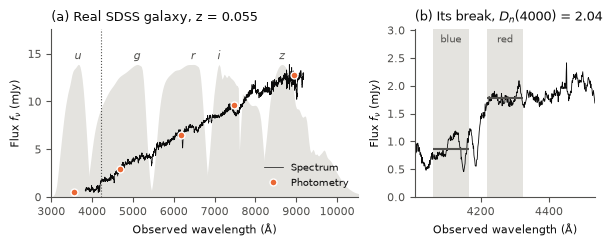

In [6]:
fig, (ax_real, ax_break) = plt.subplots(1, 2, figsize=(6.2, 2.5), gridspec_kw={"width_ratios": [1.7, 1]})
stretch = 1 + galaxy["redshift"]   # rest-frame wavelength times this gives observed wavelength

# (a) A real galaxy: its spectrum and its five photometric points
real_top = 1.15 * max(spectrum_f_nu.max(), max(band_f_nu))
shade_filters(ax_real, BANDS, bottom=0.0, height=real_top / 1.15)
ax_real.plot(spectrum_wavelength, spectrum_f_nu, color=INK, lw=0.5, label="Spectrum")
ax_real.plot(band_wavelength, band_f_nu, ls="none", marker="o", ms=5, color=PHOTOMETRY_COLOUR,
             mec=SURFACE, mew=1, label="Photometry", zorder=3)
ax_real.axvline(LAMBDA_0 * stretch, color=INK_SECONDARY, lw=0.8, ls=":")

ax_real.set_xlim(3000, 10500)
ax_real.set_ylim(0, real_top * 1.1)
ax_real.set_xlabel("Observed wavelength (Å)")
ax_real.set_ylabel(r"Flux $f_\nu$ (mJy)")
ax_real.set_title(f"(a) Real SDSS galaxy, z = {galaxy['redshift']:.3f}", color=INK, fontsize=9, loc="left")
ax_real.legend(loc="lower right", labelcolor=INK, fontsize=7)

# (b) Zoom on its break. The D_n(4000) windows are 3850-3950 and 4000-4100 A in the rest frame;
# D_n(4000) is the ratio of the mean f_nu in the red window to that in the blue window.
zoom = (spectrum_wavelength > 3800 * stretch) & (spectrum_wavelength < 4300 * stretch)
zoom_top = 1.25 * spectrum_f_nu[zoom].max()
ax_break.plot(spectrum_wavelength[zoom], spectrum_f_nu[zoom], color=INK, lw=0.6)
for name, start in [("blue", 3850), ("red", 4000)]:
    window = (spectrum_wavelength > start * stretch) & (spectrum_wavelength < (start + 100) * stretch)
    ax_break.axvspan(start * stretch, (start + 100) * stretch, color=CONTEXT_FILL, lw=0, zorder=0)
    ax_break.hlines(spectrum_f_nu[window].mean(), start * stretch, (start + 100) * stretch,
                    color=INK_SECONDARY, lw=1.5)
    ax_break.text((start + 50) * stretch, 0.97 * zoom_top, name, ha="center", va="top",
                  color=INK_SECONDARY, fontsize=7)

ax_break.set_xlim(3800 * stretch, 4300 * stretch)
ax_break.set_ylim(0, zoom_top)
ax_break.set_xlabel("Observed wavelength (Å)")
ax_break.set_ylabel(r"Flux $f_\nu$ (mJy)")
ax_break.set_title(f"(b) Its break, $D_n(4000)$ = {galaxy['d4000_n']:.2f}", color=INK, fontsize=9, loc="left")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "real_spectrum.pdf")
plt.show()

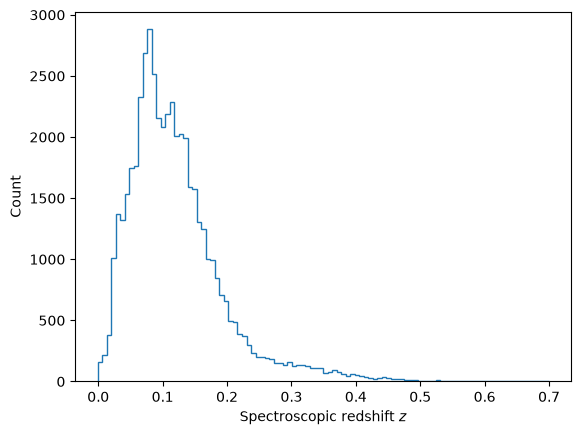

In [7]:
# Plot of redshift distribution in the SDSS dataset

plt.rcdefaults()

plt.hist(catalogue.redshift, bins=100, histtype="step")
plt.xlabel("Spectroscopic redshift $z$")
plt.ylabel("Count")
plt.show()